# 03 — Clusterização

**Entrada:** `rfm.csv`, `rfm_scaled.csv` e `rfm_scores.csv` (saídas do notebook 02)
**Saída:** `rfm_clusters.csv`, com o cluster de cada cliente em cada algoritmo

**Objetivos**
1. Escolher o número de clusters do K-Means (elbow, silhouette, Davies-Bouldin)
2. Treinar **K-Means, MiniBatch K-Means, GMM e DBSCAN**
3. Comparar os algoritmos com métricas internas e com **estabilidade entre execuções**
4. Visualizar os grupos em 2D com PCA
5. Comparar com a segmentação por regras do notebook 02
6. Perfilar cada cluster na escala original

## 1. Configuração

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, KMeans, MiniBatchKMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

SEED = 42
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

## 2. Carga

In [2]:
rfm = pd.read_csv(PROCESSED / "rfm.csv", index_col="CustomerID")
X_df = pd.read_csv(PROCESSED / "rfm_scaled.csv", index_col="CustomerID")
scores = pd.read_csv(PROCESSED / "rfm_scores.csv", index_col="CustomerID")

X = X_df.values
print(f"{X.shape[0]:,} clientes x {X.shape[1]} variáveis (R, F, M padronizadas)")

5,853 clientes x 3 variáveis (R, F, M padronizadas)


## 3. Quantos clusters? (K-Means)

Não existe um número "certo". Olhamos três sinais e escolhemos um valor que também faça sentido para o negócio:
- **Inertia (elbow):** procure o "cotovelo", onde o ganho de adicionar clusters diminui
- **Silhouette:** quanto maior, melhor separados
- **Davies-Bouldin:** quanto **menor**, melhor

In [3]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append(
        {
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X, km.labels_),
            "davies_bouldin": davies_bouldin_score(X, km.labels_),
            "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
        }
    )
selecao_k = pd.DataFrame(rows).set_index("k")
selecao_k

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"8,570.62",0.44,0.87,"6,136.25"
3,"6,353.80",0.35,1.04,"5,158.39"
4,"4,946.18",0.36,0.94,"4,971.69"
5,"4,125.20",0.34,0.96,"4,761.09"
6,"3,574.61",0.33,0.96,"4,575.01"
7,"3,200.50",0.31,0.98,"4,371.26"
8,"2,913.30",0.30,0.98,"4,197.78"
9,"2,676.45",0.29,1.03,"4,062.02"
10,"2,478.28",0.29,1.01,"3,950.65"


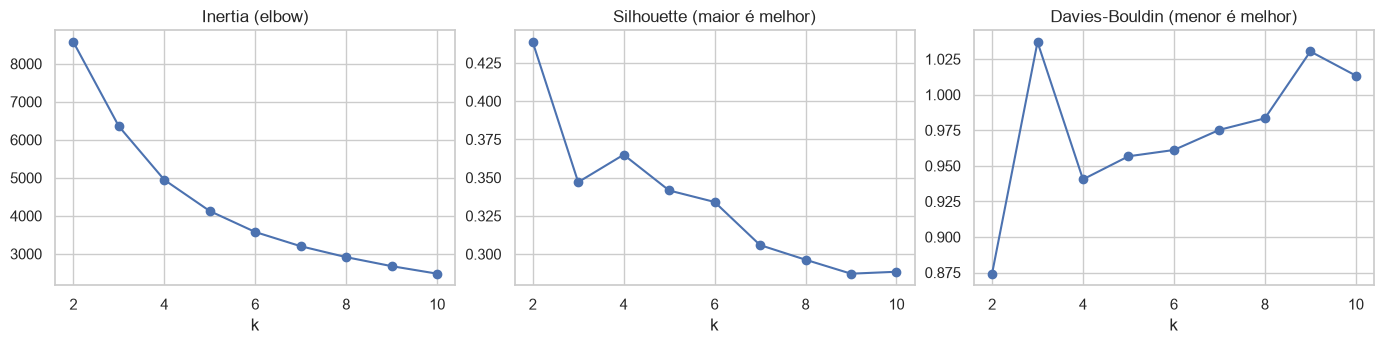

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
selecao_k["inertia"].plot(marker="o", ax=axes[0], title="Inertia (elbow)")
selecao_k["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette (maior é melhor)")
selecao_k["davies_bouldin"].plot(marker="o", ax=axes[2], title="Davies-Bouldin (menor é melhor)")
for ax in axes:
    ax.set_xlabel("k")
plt.tight_layout()
fig.savefig(FIGURES / "03_escolha_k.png", dpi=150)
plt.show()

**Decisão:** escolha `K` olhando os gráficos acima. Silhouette alto e Davies-Bouldin baixo apontam candidatos, mas para marketing costumam ser úteis entre **3 e 6 grupos**: poucos demais escondem diferenças, e muitos viram uma lista impossível de agir. Ajuste a variável abaixo e registre o motivo da escolha.

In [5]:
K = 4  # <- ajuste depois de olhar os gráficos

## 4. Treinando os modelos

K-Means, MiniBatch K-Means e GMM recebem o mesmo `K` para a comparação ser justa. O DBSCAN decide sozinho quantos grupos existem, então precisa de outros parâmetros (`eps` e `min_samples`).

In [6]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
mbk = MiniBatchKMeans(n_clusters=K, n_init=10, batch_size=1024, random_state=SEED).fit(X)
gmm = GaussianMixture(n_components=K, covariance_type="full", n_init=5, random_state=SEED).fit(X)

labels_gmm = gmm.predict(X)
print("Tamanho dos clusters (K-Means):", np.bincount(kmeans.labels_))
print("Tamanho dos clusters (GMM):    ", np.bincount(labels_gmm))

Tamanho dos clusters (K-Means): [1115 2042 1477 1219]
Tamanho dos clusters (GMM):     [1619 2199  941 1094]


### GMM: e se deixarmos o BIC escolher?

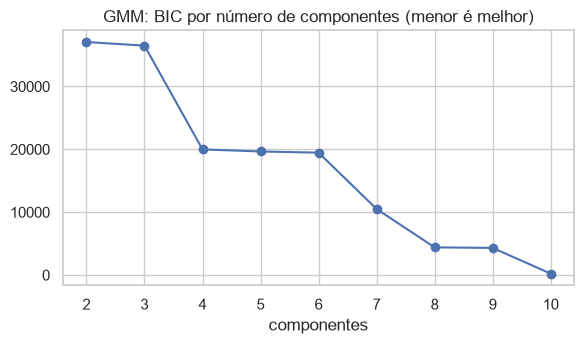

Melhor número de componentes pelo BIC: 10


In [7]:
bic = []
for k in range(2, 11):
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=SEED).fit(X)
    bic.append(g.bic(X))

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(range(2, 11), bic, marker="o")
ax.set_title("GMM: BIC por número de componentes (menor é melhor)")
ax.set_xlabel("componentes")
plt.tight_layout()
plt.show()
print("Melhor número de componentes pelo BIC:", 2 + int(np.argmin(bic)))

### DBSCAN: escolhendo `eps`

O gráfico de **k-distância** ordena, para cada cliente, a distância ao seu k-ésimo vizinho. O `eps` fica perto do "joelho" da curva: antes dele estão pontos em regiões densas, depois dele estão os isolados.

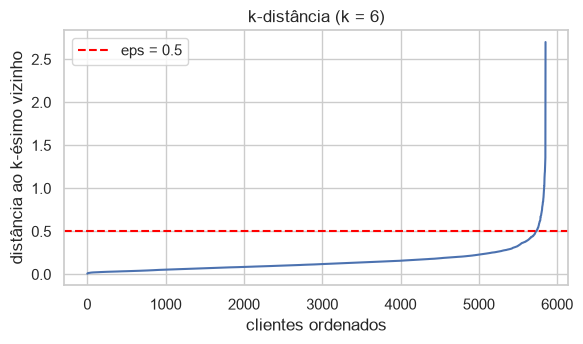

In [8]:
MIN_SAMPLES = 6   # regra prática: 2 x número de variáveis
EPS = 0.5         # <- ajuste olhando o joelho do gráfico

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X)
dist, _ = nn.kneighbors(X)
kdist = np.sort(dist[:, -1])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(kdist)
ax.axhline(EPS, color="red", linestyle="--", label=f"eps = {EPS}")
ax.set_title(f"k-distância (k = {MIN_SAMPLES})")
ax.set_xlabel("clientes ordenados")
ax.set_ylabel("distância ao k-ésimo vizinho")
ax.legend()
plt.tight_layout()
plt.show()

Para não depender só do olho no gráfico, a tabela abaixo testa vários valores de `eps`. Procure um valor que gere **mais de um cluster** sem marcar uma fatia grande dos clientes como ruído. Se o `eps` for grande demais, tudo vira um cluster só; se for pequeno demais, quase todo mundo vira ruído.

In [9]:
linhas = []
for e in [0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.7]:
    lab = DBSCAN(eps=e, min_samples=MIN_SAMPLES).fit_predict(X)
    linhas.append({"eps": e, "clusters": len(set(lab) - {-1}), "% ruído": (lab == -1).mean() * 100})
pd.DataFrame(linhas).set_index("eps")

,clusters,% ruído
eps,,
0.10,72,47.91
0.15,45,24.96
0.20,21,12.90
0.30,6,4.51
0.40,4,2.17
0.50,2,1.14
0.70,1,0.50


Atualize `EPS` na célula anterior se algum valor da tabela for melhor, e rode a célula abaixo.

In [10]:
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit(X)
labels_db = dbscan.labels_

n_cl = len(set(labels_db) - {-1})
print(f"DBSCAN encontrou {n_cl} clusters e marcou {(labels_db == -1).mean():.1%} dos clientes como ruído")

DBSCAN encontrou 2 clusters e marcou 1.1% dos clientes como ruído


## 5. Comparação dos algoritmos

As métricas são **internas** (não usam rótulo verdadeiro, que não existe aqui). Para o DBSCAN, elas são calculadas **sem os pontos de ruído**, então não são diretamente comparáveis com as dos outros: some a isso o percentual de ruído.

In [11]:
def avaliar(X, labels):
    mask = labels != -1
    n = len(set(labels[mask]))
    base = {"clusters": n, "% ruído": (~mask).mean() * 100}
    if n < 2:
        return {**base, "silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {
        **base,
        "silhouette": silhouette_score(X[mask], labels[mask]),
        "davies_bouldin": davies_bouldin_score(X[mask], labels[mask]),
        "calinski_harabasz": calinski_harabasz_score(X[mask], labels[mask]),
    }


modelos = {
    "K-Means": kmeans.labels_,
    "MiniBatch K-Means": mbk.labels_,
    "GMM": labels_gmm,
    "DBSCAN": labels_db,
}
comparacao = pd.DataFrame({nome: avaliar(X, lab) for nome, lab in modelos.items()}).T
comparacao

,clusters,% ruído,silhouette,davies_bouldin,calinski_harabasz
K-Means,4.00,0.00,0.36,0.94,"4,971.69"
MiniBatch K-Means,4.00,0.00,0.32,1.02,"4,700.58"
GMM,4.00,0.00,0.22,1.15,"3,038.19"
DBSCAN,2.00,1.14,0.28,1.01,"2,882.14"


### Estabilidade

Um bom agrupamento não deveria mudar muito só porque trocamos a semente aleatória. Rodo o K-Means com 10 sementes diferentes e meço a concordância com o resultado original usando o **Adjusted Rand Index** (1 = idêntico).

In [12]:
aris = [
    adjusted_rand_score(
        kmeans.labels_,
        KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X),
    )
    for s in range(1, 11)
]
print(f"ARI médio entre sementes: {np.mean(aris):.3f} (mín {np.min(aris):.3f}, máx {np.max(aris):.3f})")

print(f"ARI K-Means vs MiniBatch: {adjusted_rand_score(kmeans.labels_, mbk.labels_):.3f}")
print(f"ARI K-Means vs GMM:       {adjusted_rand_score(kmeans.labels_, labels_gmm):.3f}")

ARI médio entre sementes: 0.986 (mín 0.937, máx 0.992)
ARI K-Means vs MiniBatch: 0.511
ARI K-Means vs GMM:       0.345


## 6. Visualização em 2D (PCA)

Variância explicada pelas 2 componentes: [0.763 0.188] = 95.1%


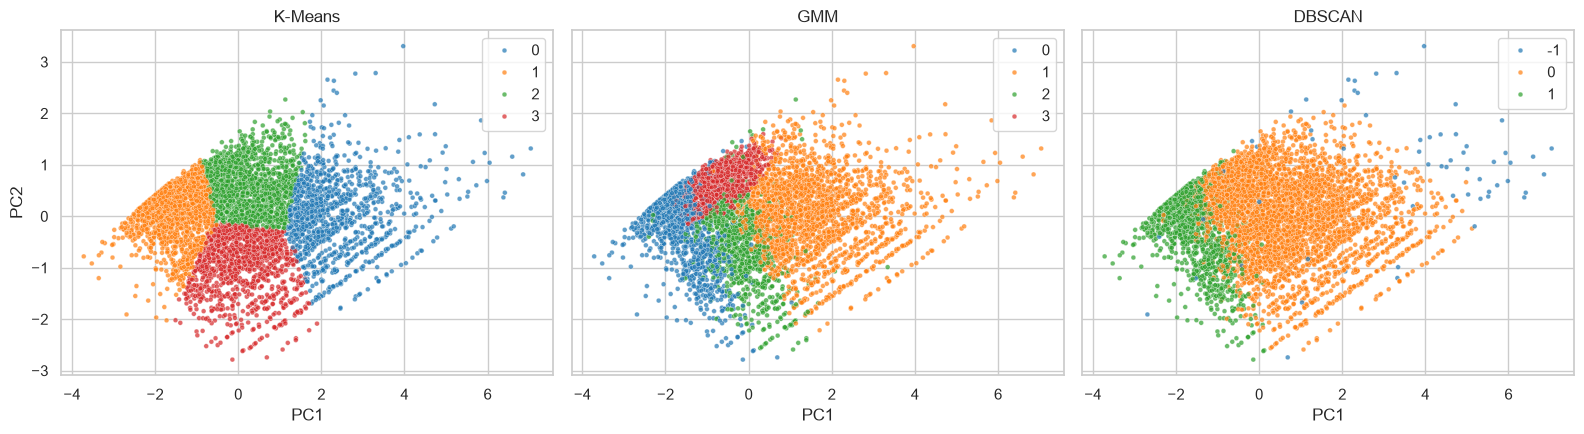

In [13]:
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X)
print("Variância explicada pelas 2 componentes:", pca.explained_variance_ratio_.round(3), "=", f"{pca.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True, sharey=True)
for ax, (nome, lab) in zip(axes, [("K-Means", kmeans.labels_), ("GMM", labels_gmm), ("DBSCAN", labels_db)]):
    sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=lab, palette="tab10", s=12, alpha=0.7, ax=ax, legend="full")
    ax.set_title(nome)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
fig.savefig(FIGURES / "03_clusters_pca.png", dpi=150)
plt.show()

## 7. Perfil dos clusters (K-Means)

Primeiro **reordeno** os rótulos pelo valor monetário mediano, assim o cluster 0 é sempre o de maior valor. Isso deixa o resultado legível e estável entre execuções.

In [14]:
def reordenar(labels, valor):
    ordem = pd.Series(valor).groupby(labels).median().sort_values(ascending=False).index
    mapa = {antigo: novo for novo, antigo in enumerate(ordem)}
    return np.array([mapa[l] for l in labels])


resultado = rfm.copy()
resultado["Cluster_KMeans"] = reordenar(kmeans.labels_, rfm["Monetary"].values)
resultado["Cluster_MiniBatch"] = reordenar(mbk.labels_, rfm["Monetary"].values)
resultado["Cluster_GMM"] = reordenar(labels_gmm, rfm["Monetary"].values)
resultado["Cluster_DBSCAN"] = labels_db
resultado["Segmento_regra"] = scores["Segmento_regra"]

perfil = (
    resultado.groupby("Cluster_KMeans")
    .agg(
        clientes=("Recency", "size"),
        recencia_mediana=("Recency", "median"),
        frequencia_mediana=("Frequency", "median"),
        valor_mediano=("Monetary", "median"),
        valor_total=("Monetary", "sum"),
    )
    .assign(pct_clientes=lambda d: d["clientes"] / d["clientes"].sum() * 100)
    .assign(pct_receita=lambda d: d["valor_total"] / d["valor_total"].sum() * 100)
)
perfil[["clientes", "pct_clientes", "recencia_mediana", "frequencia_mediana", "valor_mediano", "pct_receita"]]

,clientes,pct_clientes,recencia_mediana,frequencia_mediana,valor_mediano,pct_receita
Cluster_KMeans,,,,,,
0,1115,19.05,15.00,13.00,"5,115.36",72.14
1,1477,25.23,158.00,5.00,"1,569.36",17.97
2,1219,20.83,23.00,3.00,706.02,5.86
3,2042,34.89,400.00,1.00,289.59,4.03


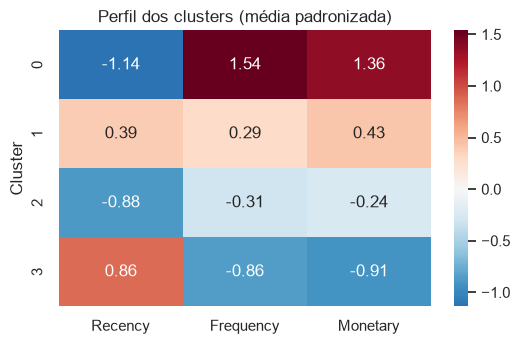

In [15]:
heat = X_df.assign(Cluster=resultado["Cluster_KMeans"]).groupby("Cluster").mean()

fig, ax = plt.subplots(figsize=(5.5, 3.6))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_title("Perfil dos clusters (média padronizada)")
plt.tight_layout()
fig.savefig(FIGURES / "03_perfil_clusters.png", dpi=150)
plt.show()

**Como ler o mapa de calor:** valores positivos significam "acima da média da base" e negativos "abaixo". Atenção: em **Recency**, valor alto é ruim (faz tempo que o cliente não compra). Um cluster com Recency alta e Frequency/Monetary baixas é típico de clientes que sumiram.

### K-Means vs segmentação por regras

In [16]:
tabela = pd.crosstab(resultado["Cluster_KMeans"], resultado["Segmento_regra"], normalize="index") * 100
print(f"ARI K-Means vs regras: {adjusted_rand_score(resultado['Cluster_KMeans'], resultado['Segmento_regra']):.3f}")
tabela.round(1)

ARI K-Means vs regras: 0.434


Segmento_regra,Campeões,Em risco,Hibernando,Leais,Novos,Potenciais
Cluster_KMeans,,,,,,
0,91.30,1.30,0.00,7.40,0.10,0.00
1,11.40,40.10,3.90,42.40,0.10,2.10
2,22.60,0.00,0.00,37.70,33.60,6.20
3,0.00,10.90,71.30,2.60,1.80,13.50


Cada linha mostra, em %, de quais segmentos por regras vêm os clientes de um cluster. Concentração em um único segmento significa que o K-Means reproduziu a regra, e mistura significa que ele encontrou uma divisão diferente.

## 8. Salvando

In [17]:
resultado.to_csv(PROCESSED / "rfm_clusters.csv")
print(f"Salvo: rfm_clusters.csv ({len(resultado):,} clientes)")

Salvo: rfm_clusters.csv (5,853 clientes)


## Conclusões e próximos passos

- Registre: o `K` escolhido e o porquê, qual algoritmo teve melhor silhouette e Davies-Bouldin, o ARI de estabilidade e o % de ruído do DBSCAN.
- Compare com honestidade: se o DBSCAN marcou muitos pontos como ruído ou o silhouette ficou baixo, diga isso no README. Dados de comportamento de compra raramente formam grupos bem separados, e métricas moderadas são esperadas.
- **Próximo notebook (`04_perfis_recomendacoes.ipynb`):** dar nome a cada cluster, escrever o perfil e propor uma ação de marketing por segmento.